In [2]:
import os
import random
import torch
import numpy as np
import pandas as pd
import copy

seed = 12345

os.environ['PYTHONHASHSEED']=str(seed)
random.seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=8):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc1 = nn.Conv2d(in_planes, in_planes // ratio, kernel_size=1, bias=False)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Conv2d(in_planes // ratio, in_planes, kernel_size=1, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc2(self.relu1(self.fc1(self.avg_pool(x))))
        max_out = self.fc2(self.relu1(self.fc1(self.max_pool(x))))
        out = avg_out + max_out
        return self.sigmoid(out)

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        assert kernel_size in (3, 7), 'Kernel size must be 3 or 7'
        padding = 3 if kernel_size == 7 else 1
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        x = torch.cat([avg_out, max_out], dim=1)
        x = self.conv1(x)
        return self.sigmoid(x)

class MultiBranchConv(nn.Module):
    def __init__(self, output_channels=16, attention=True, in_channels=16):
        super(MultiBranchConv, self).__init__()
        self.branch1 = nn.Conv2d(in_channels=1, out_channels=output_channels, kernel_size=(1, in_channels))
        self.branch2 = nn.Conv2d(in_channels=1, out_channels=output_channels, kernel_size=(2, in_channels))
        self.branch3 = nn.Conv2d(in_channels=1, out_channels=output_channels, kernel_size=(3, in_channels))
        self.branch4 = nn.Conv2d(in_channels=1, out_channels=output_channels, kernel_size=(4, in_channels))
        
        self.attn = attention
        self.ca1 = ChannelAttention(output_channels)
        self.ca2 = ChannelAttention(output_channels)
        self.ca3 = ChannelAttention(output_channels)
        self.ca4 = ChannelAttention(output_channels)
        self.sa1 = SpatialAttention(kernel_size=7)
        self.sa2 = SpatialAttention(kernel_size=7)
        self.sa3 = SpatialAttention(kernel_size=7)
        self.sa4 = SpatialAttention(kernel_size=7)

    def forward(self, x):
        out1 = F.relu(self.branch1(x))
        x_pad2 = F.pad(x, (0, 0, 0, 1))
        out2 = F.relu(self.branch2(x_pad2))
        x_pad3 = F.pad(x, (0, 0, 1, 1))
        out3 = F.relu(self.branch3(x_pad3))
        x_pad4 = F.pad(x, (0, 0, 1, 2))
        out4 = F.relu(self.branch4(x_pad4))

        if self.attn:
            out1 = out1 * self.ca1(out1) * self.sa1(out1)
            out2 = out2 * self.ca2(out2) * self.sa2(out2)
            out3 = out3 * self.ca3(out3) * self.sa3(out3)
            out4 = out4 * self.ca4(out4) * self.sa4(out4)

        out1 = out1.squeeze(-1).transpose(1, 2)
        out2 = out2.squeeze(-1).transpose(1, 2)
        out3 = out3.squeeze(-1).transpose(1, 2)
        out4 = out4.squeeze(-1).transpose(1, 2)
        output = torch.cat((out1, out2, out3, out4), dim=-1)
        return output

class CRISPRTransformerModel(nn.Module):
    def __init__(self, config):
        super(CRISPRTransformerModel, self).__init__()
        self.input_dim = 64
        self.num_layers = config.get("num_layers", 2)
        self.num_heads = config.get("num_heads", 8)
        self.dropout_prob = config["dropout_prob"]
        self.number_hidden_layers = config["number_hidder_layers"]
        self.seq_length = config.get("seq_length", 23)
        
        self.conv = MultiBranchConv(attention=config["attn"], in_channels=config.get("in_channels", 16))
        
        self.hidden_layers = []
        start_size = self.seq_length * self.input_dim
        for i in range(self.number_hidden_layers):
            layer = nn.Sequential(
                nn.Linear(start_size, start_size // 2),
                nn.GELU(),  
                nn.Dropout(self.dropout_prob)
            )
            self.hidden_layers.append(layer)
            start_size = start_size // 2
        self.hidden_layers = nn.ModuleList(self.hidden_layers)
        self.output = nn.Linear(start_size, 2)

    def forward(self, x, src_mask=None):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        for layer in self.hidden_layers:
            x = layer(x)
        x = self.output(x)
        return x


In [ ]:
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

class TrainerDataset(Dataset):
    def __init__(self, inputs, targets):
        self.inputs = torch.tensor(inputs, dtype=torch.float32).unsqueeze(1) 
        self.targets = torch.tensor(targets, dtype=torch.long)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return self.inputs[idx], self.targets[idx]

In [6]:
import torch
from torch.utils.data import DataLoader

def train_model(model, train_loader, optimizer, scheduler, criterion, device, num_epochs):
    model = model.to(device)
    history = {'train_loss': []}
    
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        
        # Training loop
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            # Loss tracking
            train_loss += loss.item()
        
        # Average loss for the epoch
        train_loss /= len(train_loader)
        history['train_loss'].append(train_loss)
        
        print(f"Epoch {epoch + 1}/{num_epochs} | Train Loss: {train_loss:.4f}")
        scheduler.step()
    
    return model, history

In [7]:
def trainer(config, train_x, train_y):
    seed = 12345
    os.environ['PYTHONHASHSEED']=str(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    train_dataset = TrainerDataset(train_x, train_y)
    train_loader = DataLoader(train_dataset, batch_size=config['batch_size'], shuffle=True)

    model = CRISPRTransformerModel(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2)
    class_weights = torch.tensor([1.0, config['pos_weight']]).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    
    trained_model, history = train_model(model, train_loader, optimizer, scheduler, criterion, device, config['epochs'])
    return trained_model, history

In [8]:
def tester(model, test_x, test_y):
    test_dataset = TrainerDataset(test_x, test_y)
    test_dataloader = DataLoader(test_dataset, batch_size=128, shuffle=False)
    model.eval()
    results = []
    true_labels = []
    with torch.no_grad():
        for test_features, test_labels in test_dataloader:
            outputs = model(test_features.to(device)).detach().to("cpu")
            results.extend(outputs)
            true_labels.extend(test_labels)
    return true_labels, results

In [9]:
class Stats:
    def __init__(self):
        self.acc = 0
        self.pre = 0
        self.re = 0
        self.f1 = 0
        self.roc = 0
        self.prc = 0
        self.tn = 0
        self.fp = 0
        self.fn = 0
        self.tp = 0
    def print(self):
        print('Accuracy: %.4f' %self.acc)
        print('Precision: %.4f' %self.pre)
        print('Recall: %.4f' %self.re)
        print('F1 Score: %.4f' %self.f1)
        print('ROC: %.4f' %self.roc)
        print('PR AUC: %.4f' %self.prc)
        print("Confusion Matrix")
        print(self.tn, "\t", self.fp)
        print(self.fn, "\t", self.tp)

In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score, roc_curve 
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import auc
from sklearn.metrics import accuracy_score
import numpy as np
import torch

def eval_matrices(model, test_x, test_y, debug = True):
    true_y, results = tester(model, test_x, test_y)
    
    # Fixed the UserWarning by explicitly adding dim=-1
    predictions = [torch.nn.functional.softmax(r, dim=-1) for r in results]
    pred_y = np.array([y[1].item() for y in predictions])
    pred_y_list = []
    test_y = np.array([y.item() for y in true_y])

    for x in pred_y:
        if(x>0.5):
            pred_y_list.append(1)
        else:
            pred_y_list.append(0)

    pred_y_list = np.array(pred_y_list)
    tn, fp, fn, tp = confusion_matrix(test_y, pred_y_list).ravel()
    
    # Generate data points for curves
    precision, recall, _ = precision_recall_curve(test_y, pred_y)
    fpr, tpr, _ = roc_curve(test_y, pred_y)
    
    auc_score = auc(recall, precision)
    acc = accuracy_score(test_y, pred_y_list)

    pr = -1
    re = -1
    f1 = -1
    try:
        pr = tp / (tp+fp)
        re = tp / (tp+fn)
        f1 = 2*pr*re / (pr+re)
    except:
        f1 = -1

    stats = Stats()
    stats.acc = acc
    stats.pre = pr
    stats.re = re
    stats.f1 = f1
    stats.roc = roc_auc_score(test_y, pred_y)
    stats.prc = auc_score
    stats.tn = tn
    stats.fp = fp
    stats.fn = fn
    stats.tp = tp

    if debug:
        print('Accuracy: %.4f' %acc)
        print('Precision: %.4f' %pr)
        print('Recall: %.4f' %re)
        print('F1 Score: %.4f' %f1)
        print('ROC:', roc_auc_score(test_y, pred_y))
        print('PR AUC: %.4f' % auc_score)

    # Package the curve data points for plotting and saving
    curve_data = { 
        'fpr': fpr, 
        'tpr': tpr, 
        'recall': recall, 
        'precision': precision, 
        'pred_y': pred_y, 
        'pred_y_list': pred_y_list, 
        'test_y': test_y 
    }

    return stats, curve_data


In [ ]:
import os
def get_dataset_path(filename):
    paths = [
        os.path.join("datasets", filename),
        os.path.join("../datasets", filename),
        filename
    ]
    for p in paths:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Could not find {filename} in any standard location.")

def one_hot_features(df):
    nucleotides = ['A', 'T', 'G', 'C']
    pairs = [f'{n1}{n2}' for n1 in nucleotides for n2 in nucleotides]
    pairwise_features = np.zeros((len(df), 23, len(pairs)))
    for idx, row in df.iterrows():
        on_seq = row['Target sgRNA']
        off_seq = row['Off Target sgRNA']
        for pos in range(23):
            pair = on_seq[pos] + off_seq[pos]
            if pair in pairs:
                pairwise_features[idx, pos, pairs.index(pair)] = 1
    return pairwise_features


In [ ]:
from sklearn.model_selection import train_test_split

# Load dataset
data_path = get_dataset_path("all_off_target.csv")
df = pd.read_csv(data_path)

train_data, test_data = train_test_split(df, stratify=df['label'], test_size=0.20, random_state=5)  


In [13]:
train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

In [14]:
train_x = one_hot_features(train_data)
test_x = one_hot_features(test_data)

In [15]:
train_y = train_data['label'].to_numpy()
test_y = test_data['label'].to_numpy()

In [ ]:
config = {
    'num_layers': 2,
    'num_heads': 4,
    'number_hidder_layers': 1,
    'dropout_prob': 0.2,
    'batch_size': 64,
    'epochs': 40,
    'learning_rate': 0.0001,
    'pos_weight': 10,
    'attn': True,
    'in_channels': 16,
    'seq_length': 23
}

model, history = trainer(config, train_x, train_y)
stats, curve_data = eval_matrices(model, test_x, test_y)

# Save the model weights
torch.save(model.state_dict(), 'crispr_transformer_model.pth')
print("Model weights saved to 'crispr_transformer_model.pth'")


Epoch 1/40 | Train Loss: 0.1181
Epoch 2/40 | Train Loss: 0.0654
Epoch 3/40 | Train Loss: 0.0428
Epoch 4/40 | Train Loss: 0.0333
Epoch 5/40 | Train Loss: 0.0292
Epoch 6/40 | Train Loss: 0.0271
Epoch 7/40 | Train Loss: 0.0257
Epoch 8/40 | Train Loss: 0.0246
Epoch 9/40 | Train Loss: 0.0239
Epoch 10/40 | Train Loss: 0.0236
Epoch 11/40 | Train Loss: 0.0269
Epoch 12/40 | Train Loss: 0.0249
Epoch 13/40 | Train Loss: 0.0240
Epoch 14/40 | Train Loss: 0.0229
Epoch 15/40 | Train Loss: 0.0222
Epoch 16/40 | Train Loss: 0.0214
Epoch 17/40 | Train Loss: 0.0206
Epoch 18/40 | Train Loss: 0.0197
Epoch 19/40 | Train Loss: 0.0190
Epoch 20/40 | Train Loss: 0.0184
Epoch 21/40 | Train Loss: 0.0180
Epoch 22/40 | Train Loss: 0.0171
Epoch 23/40 | Train Loss: 0.0168
Epoch 24/40 | Train Loss: 0.0161
Epoch 25/40 | Train Loss: 0.0162
Epoch 26/40 | Train Loss: 0.0157
Epoch 27/40 | Train Loss: 0.0156
Epoch 28/40 | Train Loss: 0.0154
Epoch 29/40 | Train Loss: 0.0151
Epoch 30/40 | Train Loss: 0.0150
Epoch 31/40 | Train

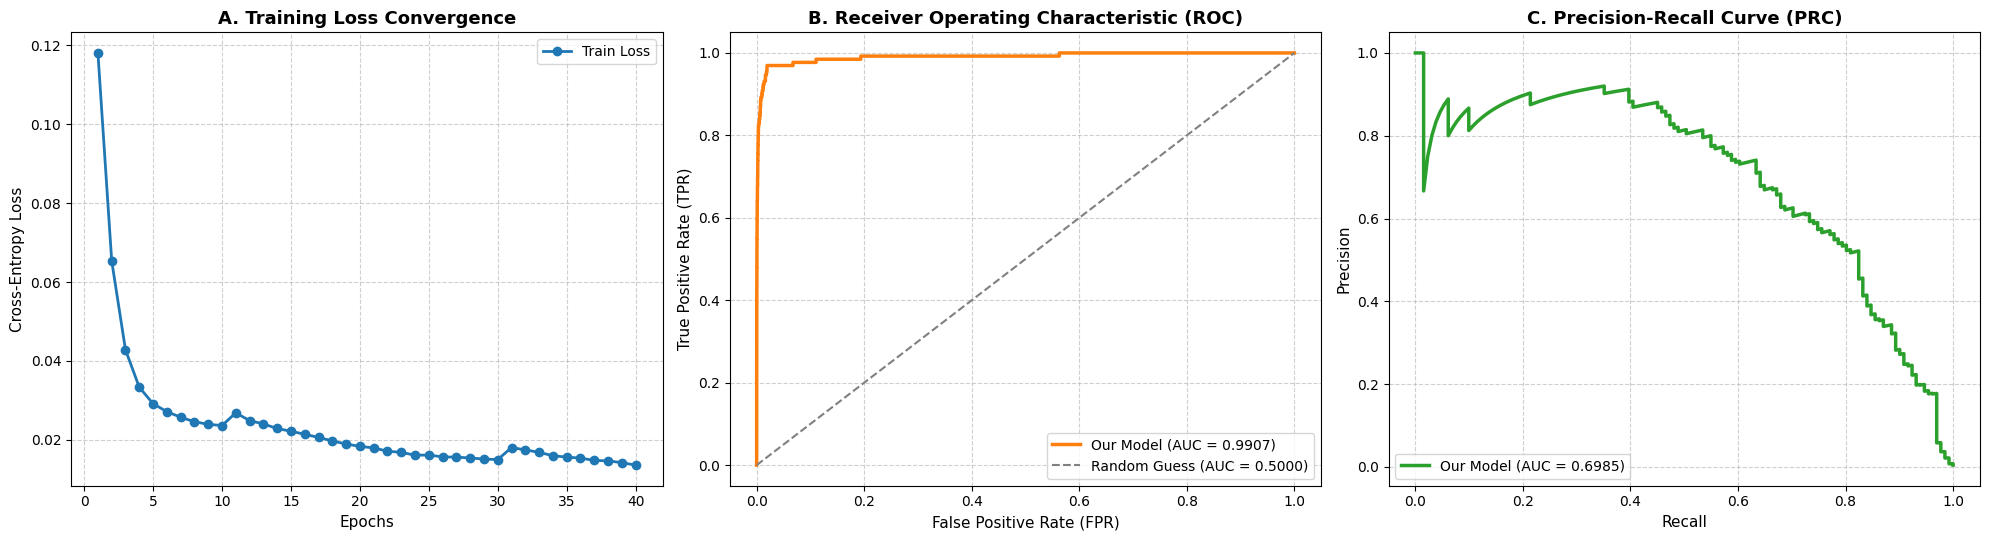

🎉 Success! Graphs generated and raw data coordinates saved as 'crispr_model_curves.npz'.


In [17]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Set up the plotting canvas (1 row, 3 columns)
plt.figure(figsize=(20, 5.5))

# --- Graph A: Learning Curve (Training Loss) ---
plt.subplot(1, 3, 1)
epochs = range(1, len(history['train_loss']) + 1)
plt.plot(epochs, history['train_loss'], marker='o', color='#1f77b4', linewidth=2, label='Train Loss')
plt.title('A. Training Loss Convergence', fontsize=13, fontweight='bold')
plt.xlabel('Epochs', fontsize=11)
plt.ylabel('Cross-Entropy Loss', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)

# --- Graph B: ROC AUC Curve (TPR vs FPR) ---
plt.subplot(1, 3, 2)
plt.plot(curve_data['fpr'], curve_data['tpr'], color='#ff7f0e', linewidth=2.5, 
         label=f"Our Model (AUC = {stats.roc:.4f})")
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.5, label='Random Guess (AUC = 0.5000)')
plt.title('B. Receiver Operating Characteristic (ROC)', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="lower right", fontsize=10)

# --- Graph C: PR AUC Curve (Precision vs Recall) ---
plt.subplot(1, 3, 3)
plt.plot(curve_data['recall'], curve_data['precision'], color='#2ca02c', linewidth=2.5, 
         label=f"Our Model (AUC = {stats.prc:.4f})")
plt.title('C. Precision-Recall Curve (PRC)', fontsize=13, fontweight='bold')
plt.xlabel('Recall', fontsize=11)
plt.ylabel('Precision', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="lower left", fontsize=10)

# Render layout nicely
plt.tight_layout()
plt.show()

# 2. Save all numeric array data points for future use or external graphing tools
np.savez('crispr_model_curves.npz', 
         epochs=np.array(list(epochs)),
         train_loss=np.array(history['train_loss']),
         fpr=curve_data['fpr'], 
         tpr=curve_data['tpr'], 
         recall=curve_data['recall'], 
         precision=curve_data['precision'])

print("🎉 Success! Graphs generated and raw data coordinates saved as 'crispr_model_curves.npz'.")


In [18]:
import numpy as np
from sklearn.metrics import roc_auc_score, f1_score, auc, precision_recall_curve

def compute_metric_bootstraps(test_y, pred_y, pred_y_list, n_bootstraps=1000, alpha=0.05, seed=12345):
    """
    Computes both 95% Confidence Intervals and Mean +- Std for model metrics using bootstrapping.
    """
    bootstrapped_roc = []
    bootstrapped_f1 = []
    bootstrapped_pr_auc = []
    
    n_samples = len(test_y)
    rng = np.random.default_rng(seed=seed)
    
    print(f"Running {n_bootstraps} bootstrap iterations...")
    for i in range(n_bootstraps):
        # Resample indices with replacement
        boot_indices = rng.choice(n_samples, size=n_samples, replace=True)
        
        boot_y = test_y[boot_indices]
        boot_pred = pred_y[boot_indices]
        boot_pred_labels = pred_y_list[boot_indices]
        
        # Ensure bootstrap sample contains both classes to avoid ROC AUC errors
        if len(np.unique(boot_y)) < 2:
            continue
            
        # Calculate metrics for this bootstrap sample
        boot_roc = roc_auc_score(boot_y, boot_pred)
        boot_f1 = f1_score(boot_y, boot_pred_labels, zero_division=0)
        
        precision, recall, _ = precision_recall_curve(boot_y, boot_pred)
        boot_pr = auc(recall, precision)
        
        bootstrapped_roc.append(boot_roc)
        bootstrapped_f1.append(boot_f1)
        bootstrapped_pr_auc.append(boot_pr)
        
    # 1. Calculate Mean and Standard Deviation
    mean_roc, std_roc = np.mean(bootstrapped_roc), np.std(bootstrapped_roc)
    mean_f1, std_f1 = np.mean(bootstrapped_f1), np.std(bootstrapped_f1)
    mean_pr, std_pr = np.mean(bootstrapped_pr_auc), np.std(bootstrapped_pr_auc)
        
    # 2. Calculate Percentile Confidence Intervals (e.g., 2.5th and 97.5th)
    low_p = (alpha / 2.0) * 100
    high_p = (1.0 - alpha / 2.0) * 100
    
    ci_roc = (np.percentile(bootstrapped_roc, low_p), np.percentile(bootstrapped_roc, high_p))
    ci_f1 = (np.percentile(bootstrapped_f1, low_p), np.percentile(bootstrapped_f1, high_p))
    ci_pr = (np.percentile(bootstrapped_pr_auc, low_p), np.percentile(bootstrapped_pr_auc, high_p))
    
    print("\n--- Research Report: Model Performance Metrics ---")
    print(f"ROC AUC  : {mean_roc:.4f} ± {std_roc:.4f}  (95% CI: [{ci_roc[0]:.4f}, {ci_roc[1]:.4f}])")
    print(f"F1-Score : {mean_f1:.4f} ± {std_f1:.4f}  (95% CI: [{ci_f1[0]:.4f}, {ci_f1[1]:.4f}])")
    print(f"PR AUC   : {mean_pr:.4f} ± {std_pr:.4f}  (95% CI: [{ci_pr[0]:.4f}, {ci_pr[1]:.4f}])")
    
    return {
        'roc': {'mean': mean_roc, 'std': std_roc, 'ci': ci_roc},
        'f1': {'mean': mean_f1, 'std': std_f1, 'ci': ci_f1},
        'pr_auc': {'mean': mean_pr, 'std': std_pr, 'ci': ci_pr}
    }

# Run bootstrapping test
bootstrap_results = compute_metric_bootstraps(
    curve_data['test_y'], 
    curve_data['pred_y'], 
    curve_data['pred_y_list']
)


Running 1000 bootstrap iterations...

--- Research Report: Model Performance Metrics ---
ROC AUC  : 0.9908 ± 0.0047  (95% CI: [0.9798, 0.9974])
F1-Score : 0.6062 ± 0.0315  (95% CI: [0.5427, 0.6667])
PR AUC   : 0.6999 ± 0.0447  (95% CI: [0.6130, 0.7867])
